In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = "../data/raw/"

cols = (
    ["unit", "cycle"]
    + [f"op{i}" for i in range(1, 4)]
    + [f"s{i}" for i in range(1, 22)]
)

train = pd.read_csv(DATA + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(DATA + "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul = pd.read_csv(DATA + "RUL_FD001.txt", header=None, names=["RUL"])

print(train.shape, test.shape, rul.shape)

(20631, 26) (13096, 26) (100, 1)


In [2]:
max_cycle = train.groupby("unit")["cycle"].transform("max")
train["RUL_raw"] = max_cycle - train["cycle"]

print(train[["unit", "cycle", "RUL_raw"]].head())
print(train[["unit", "cycle", "RUL_raw"]].tail())
print("min RUL:", train["RUL_raw"].min(), "| max RUL:", train["RUL_raw"].max())

   unit  cycle  RUL_raw
0     1      1      191
1     1      2      190
2     1      3      189
3     1      4      188
4     1      5      187
       unit  cycle  RUL_raw
20626   100    196        4
20627   100    197        3
20628   100    198        2
20629   100    199        1
20630   100    200        0
min RUL: 0 | max RUL: 361


In [3]:
CAP = 125
train["RUL"] = train["RUL_raw"].clip(upper=CAP)

print(train["RUL"].describe())

count    20631.000000
mean        86.829286
std         41.673699
min          0.000000
25%         51.000000
50%        103.000000
75%        125.000000
max        125.000000
Name: RUL, dtype: float64


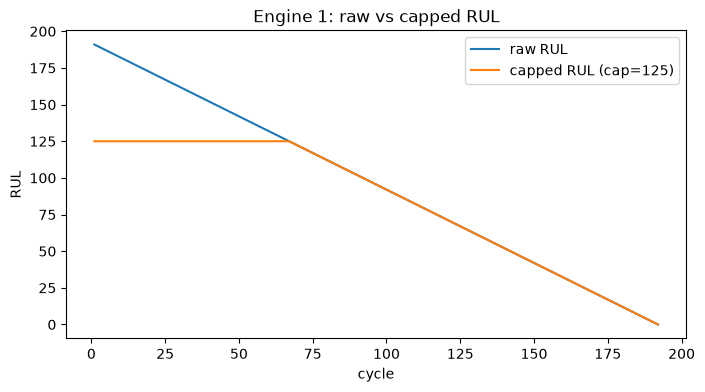

In [4]:
eng = train[train["unit"] == 1]

plt.figure(figsize=(8, 4))
plt.plot(eng["cycle"], eng["RUL_raw"], label="raw RUL")
plt.plot(eng["cycle"], eng["RUL"], label=f"capped RUL (cap={CAP})")
plt.xlabel("cycle")
plt.ylabel("RUL")
plt.title("Engine 1: raw vs capped RUL")
plt.legend()
plt.show()

In [5]:
sensor_cols = [c for c in cols if c.startswith("s")]
setting_cols = ["op1", "op2", "op3"]

std = train[setting_cols + sensor_cols].std()
drop_cols = std[std < 0.01].index.tolist()
keep_sensors = [c for c in sensor_cols if c not in drop_cols]

print("Dropped:", drop_cols)
print("Kept (", len(keep_sensors), "):", keep_sensors)

Dropped: ['op1', 'op2', 'op3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
Kept ( 14 ): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [6]:
test_last = test.groupby("unit")["cycle"].max().reset_index(name="last_cycle")
test_last["true_RUL"] = rul["RUL"].values
test_last["true_RUL_capped"] = test_last["true_RUL"].clip(upper=CAP)
test_last["implied_total_life"] = test_last["last_cycle"] + test_last["true_RUL"]

print(test_last.head())
print()
print("engines with true RUL > 125:", (test_last["true_RUL"] > CAP).sum())
print(test_last["true_RUL"].describe())

   unit  last_cycle  true_RUL  true_RUL_capped  implied_total_life
0     1          31       112              112                 143
1     2          49        98               98                 147
2     3         126        69               69                 195
3     4         106        82               82                 188
4     5          98        91               91                 189

engines with true RUL > 125: 11
count    100.00000
mean      75.52000
std       41.76497
min        7.00000
25%       32.75000
50%       86.00000
75%      112.25000
max      145.00000
Name: true_RUL, dtype: float64


## Findings: RUL labels and sensor selection (FD001)

**1. Training RUL**
- For each training row, RUL = (engine's last cycle) − (current cycle).
- At an engine's last cycle, RUL = 0, which is the moment of failure.
- Engine 1 runs for 192 cycles, so its RUL starts at 191. The largest raw RUL in the whole training set is 361.

**2. Capping at 125**
- Early in an engine's life there is no visible degradation, so raw labels like "290 left" vs "250 left" describe nearly identical sensor readings. That is label noise.
- I cap RUL at 125, so every row with more than 125 cycles left is labelled "healthy" (125).
- For engine 1, the capped RUL stays flat at 125 until about cycle 67 (192 − 125), then follows the raw RUL down to 0.
- After capping, the training RUL has a mean of about 86.8, and more than a quarter of the rows sit at the cap.
- Without the cap, large early-life labels would dominate the error and the model would be judged on a part of the life that the sensors cannot reveal.

**3. Sensor selection**
- I computed the standard deviation of every sensor and operating setting on the training data and dropped anything below 0.01.
- Dropped (10): op1, op2, op3, s1, s5, s6, s10, s16, s18, s19. These are constant or almost constant, so they carry no degradation information.
- FD001 has only one operating condition, so the three operating settings add nothing here.
- Kept (14): s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s15, s17, s20, s21.
- A rule-based cut-off is reproducible, so I can reuse it on FD002-FD004.

**4. Test labels**
- Training engines run to failure, so every row has a RUL label.
- Test engines are cut off before failure, and RUL_FD001.txt gives one true remaining-life value per engine (row 1 = engine 1, and so on).
- So the test set has one label per engine, and I evaluate on each engine's last observed cycle.
- 11 of the 100 test engines have a true RUL above 125, so I cap the test labels at 125 too, to match training.
- Sanity check: last observed cycle + true RUL gives an implied total life in the same range as the training lifetimes, so the alignment between the test data and the RUL file is correct.
- Test engines are observed for very different numbers of cycles (engine 1 only 31), which affects the window size I can use for sequence models.